# GAN et espace latent — Q1 à Q14
Amjad AAYD — [information masquée]

Code pédagogique commenté. Les poids DCGAN et LeNet5 sont des **remplacements entraînés localement**, pas ceux du professeur.

## Environnement et fonctions de visualisation

In [1]:
# Importer les outils et fixer les graines pour documenter l'expérience.
from pathlib import Path
import json, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from sklearn import datasets as skdata
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
from sklearn.manifold import TSNE
from threadpoolctl import threadpool_limits
random.seed(42); np.random.seed(42); torch.manual_seed(42)
torch.set_num_threads(4)
# Préférer MPS, puis CUDA, puis le CPU conformément au sujet StyleGAN.
def choisir_device():
    if torch.backends.mps.is_available(): return torch.device('mps')
    if torch.cuda.is_available(): return torch.device('cuda')
    return torch.device('cpu')
device=choisir_device(); print('Périphérique :',device)
Path('figures').mkdir(exist_ok=True);Path('models').mkdir(exist_ok=True)
def figure(nom):
    plt.tight_layout();plt.savefig('figures/'+nom+'.png',dpi=140);plt.show();plt.close()
def grille(images,nom,ncol=10):
    images=images.detach().cpu(); nrow=(len(images)+ncol-1)//ncol
    fig,axes=plt.subplots(nrow,ncol,figsize=(ncol,nrow),squeeze=False)
    for ax in axes.flat:ax.axis('off')
    for ax,img in zip(axes.flat,images):ax.imshow(img.squeeze(),cmap='gray',vmin=-1,vmax=1)
    figure(nom)


Périphérique : cuda


## Q1–Q4 : cercle, architectures Sequential et apprentissage antagoniste
Le coût du discriminateur est l’opposé de la log-vraisemblance du sujet. Pour G, on minimise directement la forme minimax log(1-D(G(z))) prescrite ; detach empêche le gradient de D de modifier G.

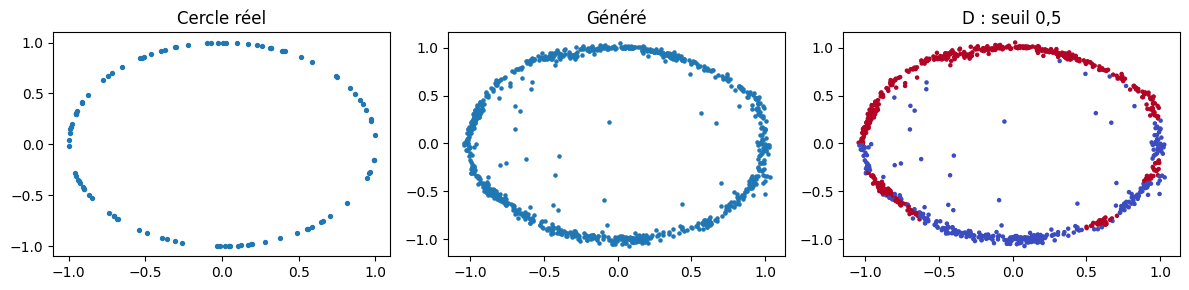

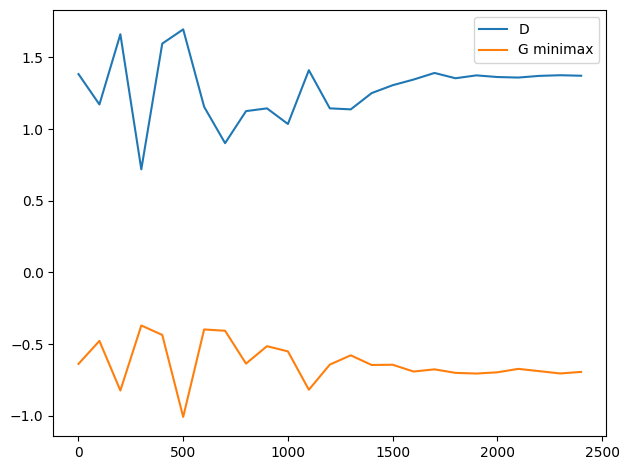

Erreur radiale moyenne : 0.025414543226361275


In [2]:
# Construire les réseaux à trois couches linéaires.
def reseaux(dim,latent=10):
    G=nn.Sequential(nn.Linear(latent,64),nn.ReLU(),nn.Linear(64,64),nn.ReLU(),nn.Linear(64,dim)).to(device)
    D=nn.Sequential(nn.Linear(dim,64),nn.LeakyReLU(.2),nn.Linear(64,64),nn.LeakyReLU(.2),nn.Linear(64,1),nn.Sigmoid()).to(device)
    return G,D
# Alterner une mise à jour D puis une mise à jour G.
def apprendre_points(X,latent=10,steps=2500):
    G,D=reseaux(X.shape[1],latent); x=torch.tensor(X,dtype=torch.float32,device=device)
    og=torch.optim.Adam(G.parameters(),lr=.001);od=torch.optim.Adam(D.parameters(),lr=.001);hist=[]
    for step in range(steps):
        real=x[torch.randint(len(x),(128,),device=device)];z=torch.randn(128,latent,device=device)
        fake=G(z);od.zero_grad()
        lossd=-(torch.log(D(real).clamp_min(1e-7)).mean()+torch.log((1-D(fake.detach())).clamp_min(1e-7)).mean())
        lossd.backward();od.step();og.zero_grad()
        lossg=torch.log((1-D(G(z))).clamp_min(1e-7)).mean();lossg.backward();og.step()
        if step%100==0:hist.append([step,lossd.item(),lossg.item()])
    with torch.no_grad():fake=G(torch.randn(1000,latent,device=device));pred=D(fake).flatten().cpu().numpy()
    return G,D,fake.cpu().numpy(),np.array(hist),pred
X=np.random.randn(100,2);X/=np.linalg.norm(X,axis=1)[:,None]
G,D,fake,hist,pred=apprendre_points(X)
fig,ax=plt.subplots(1,3,figsize=(12,3));ax[0].scatter(*X.T,s=8);ax[0].set_title('Cercle réel');ax[1].scatter(*fake.T,s=5);ax[1].set_title('Généré');ax[2].scatter(*fake.T,c=pred>=.5,s=5,cmap='coolwarm');ax[2].set_title('D : seuil 0,5');figure('cercle')
plt.plot(hist[:,0],hist[:,1],label='D');plt.plot(hist[:,0],hist[:,2],label='G minimax');plt.legend();figure('pertes_cercle')
print('Erreur radiale moyenne :',float(np.abs(np.linalg.norm(fake,axis=1)-1).mean()))


## Q5–Q6 optionnelles : demi-lunes et Swiss roll
Comparer la couverture des distributions. Une petite dimension latente peut limiter la couverture ; une image seule ne démontre pas une impossibilité mathématique.

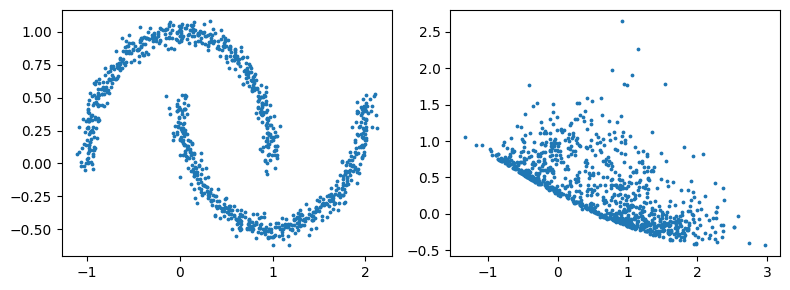

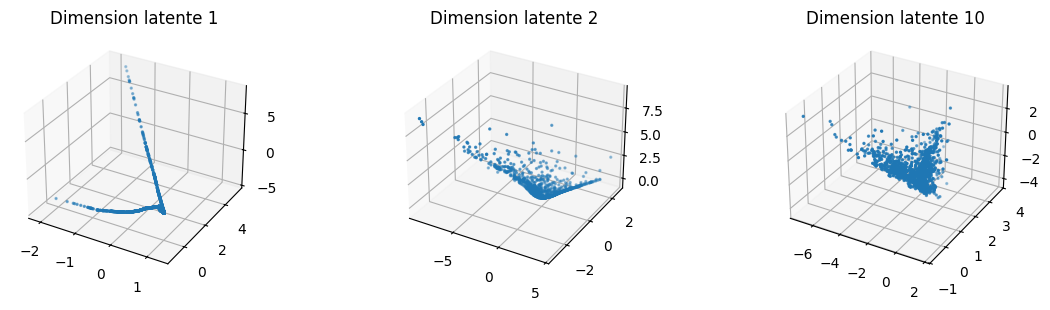

In [3]:
# Répéter le même entraînement sur les deux distributions demandées.
moons,_=skdata.make_moons(n_samples=1000,noise=.05,random_state=42)
_,_,f,_,_=apprendre_points(moons,steps=2000)
fig,ax=plt.subplots(1,2,figsize=(8,3));ax[0].scatter(*moons.T,s=3);ax[1].scatter(*f.T,s=3);figure('demi_lunes')
swiss,_=skdata.make_swiss_roll(n_samples=2000,noise=.05,random_state=42);swiss=(swiss-swiss.mean(0))/swiss.std(0)
fig=plt.figure(figsize=(12,3))
for i,latent in enumerate([1,2,10]):
    _,_,f,_,_=apprendre_points(swiss,latent=latent,steps=2000)
    ax=fig.add_subplot(1,3,i+1,projection='3d');ax.scatter(*f.T,s=2);ax.set_title('Dimension latente '+str(latent))
figure('swiss_roll')


## Q7 : GAN conditionnel MNIST

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<00:31, 312kB/s]

  1%|          | 98.3k/9.91M [00:00<00:20, 481kB/s]

  2%|▏         | 164k/9.91M [00:00<00:18, 533kB/s] 

  3%|▎         | 262k/9.91M [00:00<00:14, 673kB/s]

  5%|▌         | 524k/9.91M [00:00<00:07, 1.29MB/s]

... (14 outputs left out)

100%|██████████| 1.65M/1.65M [00:00<00:00, 2.26MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 4.50MB/s]

Batch : torch.Size([256, 1, 28, 28]) pixels : -1.0 1.0


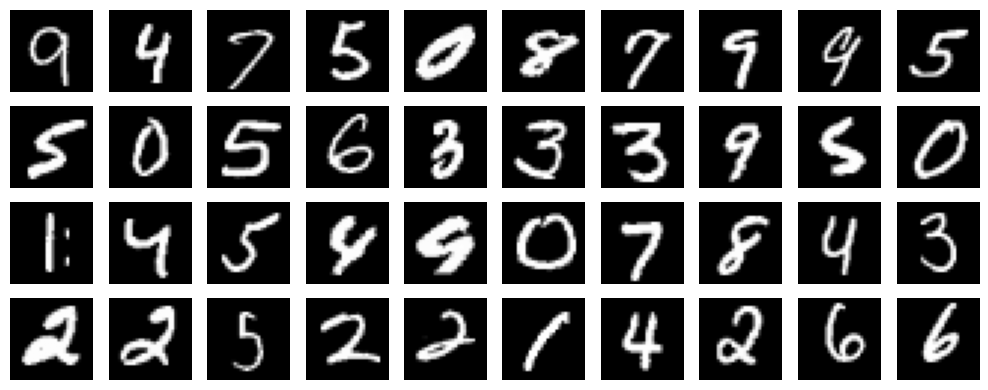

In [4]:
# Charger les vrais jeux MNIST, avec un DataLoader sans workers supplémentaires.
train=datasets.MNIST('../data',train=True,download=True,transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize((.5,),(.5,))]))
test=datasets.MNIST('../data',train=False,download=True,transform=train.transform)
loader=DataLoader(train,batch_size=256,shuffle=True,num_workers=0)
images,labels=next(iter(loader));print('Batch :',images.shape,'pixels :',float(images.min()),float(images.max()))
grille(images[:40],'images_reelles')


## Conditionnement one-hot et apprentissage
On concatène le chiffre encodé en one-hot à z et à l’image pour G et D. Pour l’apprentissage image, la perte non saturante -log D(G(z)) stabilise les gradients ; cette adaptation est explicitée par rapport au coût minimax de Q2.

cGAN époque 1 [1.0744180577866576, 0.9901742897135146]


cGAN époque 2 [0.677398038734781, 2.12212670857602]


cGAN époque 3 [0.6912869921390047, 2.3766479238550713]


cGAN époque 4 [0.5522540389857393, 2.9157496472622486]


cGAN époque 5 [0.5109667006959306, 2.987104358825278]


cGAN époque 6 [0.5418365363110887, 3.1648079151802873]


... (5 outputs left out)

cGAN époque 12 [0.45566055888825274, 3.2369931753645553]


cGAN époque 13 [0.4174711464567387, 3.4223415141410016]


cGAN époque 14 [0.5251318702038298, 3.0829169702022634]


cGAN époque 15 [0.5950569151563847, 2.7593915571557717]


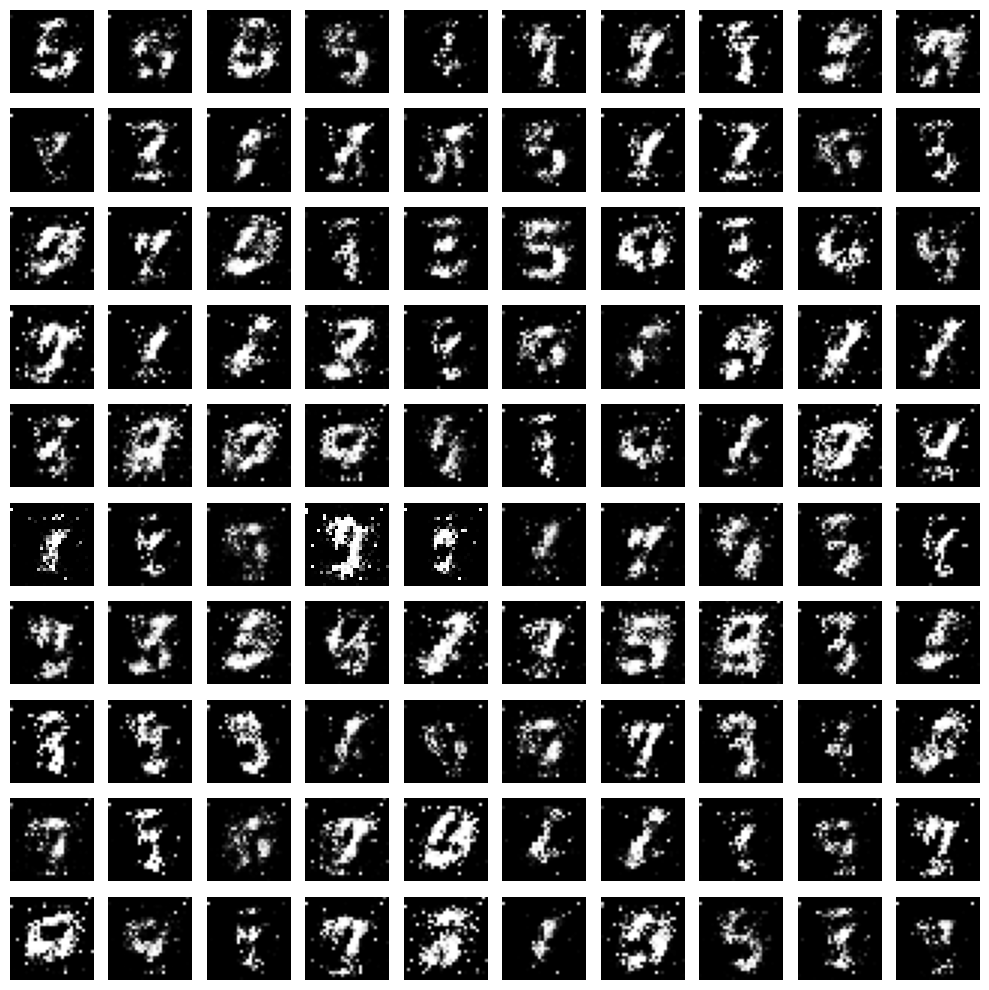

In [5]:
# Définir un GAN conditionnel entièrement connecté.
class CG(nn.Module):
    def __init__(self):
        super().__init__();self.net=nn.Sequential(nn.Linear(110,256),nn.LeakyReLU(.2),nn.Linear(256,512),nn.LeakyReLU(.2),nn.Linear(512,784),nn.Tanh())
    def forward(self,z,y):return self.net(torch.cat([z,F.one_hot(y,10).float()],1)).view(-1,1,28,28)
class CD(nn.Module):
    def __init__(self):
        super().__init__();self.net=nn.Sequential(nn.Linear(794,512),nn.LeakyReLU(.2),nn.Linear(512,256),nn.LeakyReLU(.2),nn.Linear(256,1))
    def forward(self,x,y):return self.net(torch.cat([x.flatten(1),F.one_hot(y,10).float()],1))
cg,cd=CG().to(device),CD().to(device)
og=torch.optim.Adam(cg.parameters(),lr=.0002,betas=(.5,.999));od=torch.optim.Adam(cd.parameters(),lr=.0002,betas=(.5,.999));bce=nn.BCEWithLogitsLoss();ch=[]
for epoch in range(15):
    ds=gs=0
    for x,y in loader:
        x,y=x.to(device),y.to(device);z=torch.randn(len(x),100,device=device);f=cg(z,y)
        od.zero_grad();ld=bce(cd(x,y),torch.ones(len(x),1,device=device))+bce(cd(f.detach(),y),torch.zeros(len(x),1,device=device));ld.backward();od.step()
        og.zero_grad();lg=bce(cd(cg(z,y),y),torch.ones(len(x),1,device=device));lg.backward();og.step();ds+=ld.item();gs+=lg.item()
    ch.append([ds/len(loader),gs/len(loader)]);print('cGAN époque',epoch+1,ch[-1])
with torch.no_grad():grille(cg(torch.randn(100,100,device=device),torch.arange(10,device=device).repeat_interleave(10)),'cgan_conditionnel')
torch.save(cg.state_dict(),'models/cgan.pt')


## Q8–Q9 : DCGAN et LeNet5 de remplacement
Le sujet ne fournit pas de poids. Nous entraînons les deux modèles sur MNIST puis sauvegardons leurs paramètres. Les expériences suivantes réutilisent ces modèles localement entraînés. LeNet5 fournit des pseudo-étiquettes, avec ses propres erreurs.

DCGAN époque 1 [1.3583446974449969, 0.6919302608104463]


DCGAN époque 2 [1.3621209525047464, 0.7263610289451924]


DCGAN époque 3 [1.334839710783451, 0.7541064800100123]


DCGAN époque 4 [1.321819956759189, 0.762231606625496]


DCGAN époque 5 [1.3286584296125046, 0.7408816931095529]


DCGAN époque 6 [1.3352357610743097, 0.7390980215782815]


... (9 outputs left out)

LeNet5 époque 1 perte dernier batch 0.1863781213760376


LeNet5 époque 2 perte dernier batch 0.1451692134141922


LeNet5 époque 3 perte dernier batch 0.11428334563970566


Exactitude LeNet5 test réel : 0.9793


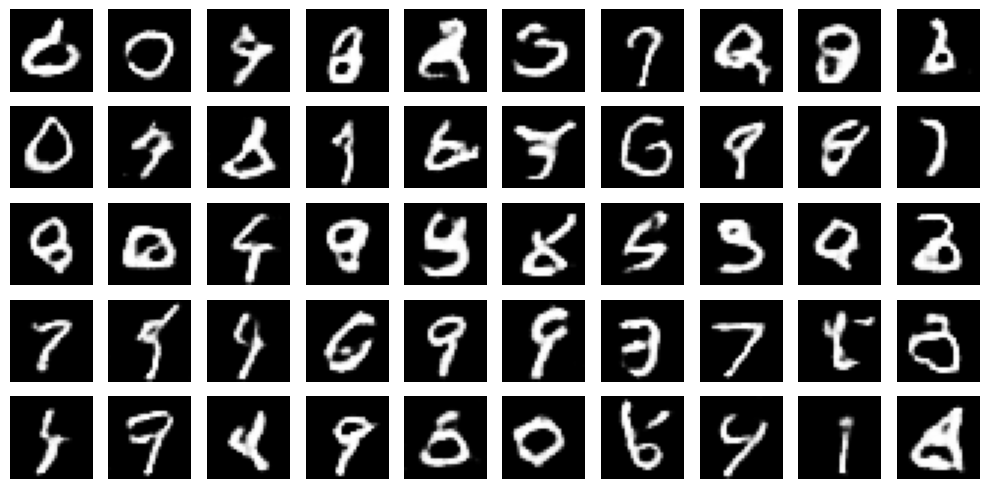

In [6]:
# Générateur convolutionnel optionnel utilisé pour l'espace latent de dimension 100.
dg=nn.Sequential(nn.ConvTranspose2d(100,128,7),nn.BatchNorm2d(128),nn.ReLU(),nn.ConvTranspose2d(128,64,4,2,1),nn.BatchNorm2d(64),nn.ReLU(),nn.ConvTranspose2d(64,1,4,2,1),nn.Tanh()).to(device)
dd=nn.Sequential(nn.Conv2d(1,32,4,2,1),nn.LeakyReLU(.2),nn.Conv2d(32,64,4,2,1),nn.LeakyReLU(.2),nn.Flatten(),nn.Linear(64*7*7,1)).to(device)
og=torch.optim.Adam(dg.parameters(),lr=.0002,betas=(.5,.999));od=torch.optim.Adam(dd.parameters(),lr=.0002,betas=(.5,.999));dh=[]
for epoch in range(15):
    ds=gs=0
    for x,_ in loader:
        x=x.to(device);z=torch.randn(len(x),100,1,1,device=device);f=dg(z)
        od.zero_grad();ld=bce(dd(x),torch.ones(len(x),1,device=device))+bce(dd(f.detach()),torch.zeros(len(x),1,device=device));ld.backward();od.step()
        og.zero_grad();lg=bce(dd(dg(z)),torch.ones(len(x),1,device=device));lg.backward();og.step();ds+=ld.item();gs+=lg.item()
    dh.append([ds/len(loader),gs/len(loader)]);print('DCGAN époque',epoch+1,dh[-1])
dg.eval();torch.save(dg.state_dict(),'models/dcgan_remplacement.pt')
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__();self.features=nn.Sequential(nn.Conv2d(1,6,5,padding=2),nn.Tanh(),nn.AvgPool2d(2),nn.Conv2d(6,16,5),nn.Tanh(),nn.AvgPool2d(2));self.head=nn.Sequential(nn.Flatten(),nn.Linear(400,120),nn.Tanh(),nn.Linear(120,84),nn.Tanh(),nn.Linear(84,10))
    def forward(self,x):return self.head(self.features(x))
clf=LeNet5().to(device);opt=torch.optim.Adam(clf.parameters(),lr=.001)
for epoch in range(3):
    for x,y in loader:
        opt.zero_grad();loss=F.cross_entropy(clf(x.to(device)),y.to(device));loss.backward();opt.step()
    print('LeNet5 époque',epoch+1,'perte dernier batch',loss.item())
clf.eval();correct=total=0
with torch.no_grad():
    for x,y in DataLoader(test,batch_size=256,num_workers=0):correct+=(clf(x.to(device)).argmax(1).cpu()==y).sum().item();total+=len(y)
print('Exactitude LeNet5 test réel :',correct/total);torch.save(clf.state_dict(),'models/lenet5_remplacement.pt')
# Accepter les deux formes de codes indiquées par le sujet.
def code2image(z):
    with torch.no_grad():return dg(z.to(device).reshape(-1,100,1,1)).squeeze(1)
z=torch.randn(1000,100,device=device);synth=code2image(z)
assert synth.shape==(1000,28,28)
grille(synth[:50],'dcgan_generations')


## Q10–Q11 : distribution des chiffres et séparabilité
Les scores sur images synthétiques utilisent les pseudo-étiquettes de LeNet5. Ils ne constituent pas une validation humaine indépendante. La SVM réelle est entraînée sur un sous-ensemble reproductible de 10 000 images pour limiter le calcul.

Occurrences : [102, 71, 107, 102, 79, 91, 85, 121, 113, 129]


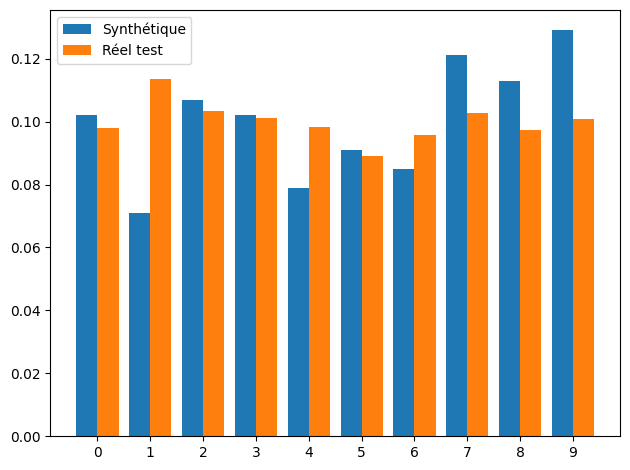

{'reel_vers_reel': 0.905, 'reel_vers_synthetique': 0.642, 'synthetique_vers_reel': 0.7761}


265

In [7]:
# Classer les 1000 images synthétiques et comparer les occurrences.
with torch.no_grad():pseudo=clf(synth[:,None]).argmax(1).cpu().numpy()
counts=np.bincount(pseudo,minlength=10);print('Occurrences :',counts.tolist())
plt.bar(np.arange(10)-.2,counts/1000,.4,label='Synthétique');plt.bar(np.arange(10)+.2,np.bincount(test.targets.numpy(),minlength=10)/len(test),.4,label='Réel test');plt.xticks(range(10));plt.legend();figure('distribution_classes')
# Apprendre une SVM linéaire sur des images réelles puis sur des images synthétiques.
xreal=(train.data[:10000].numpy().reshape(10000,-1)/255)*2-1;yreal=train.targets[:10000].numpy()
xtest=(test.data.numpy().reshape(len(test),-1)/255)*2-1;ytest=test.targets.numpy();xs=synth.cpu().numpy().reshape(1000,-1)
with threadpool_limits(limits=4):
    svm=LinearSVC(C=.01,max_iter=4000,dual='auto');svm.fit(xreal,yreal)
    rr=accuracy_score(ytest,svm.predict(xtest));rs=accuracy_score(pseudo,svm.predict(xs))
    svm2=LinearSVC(C=.01,max_iter=4000,dual='auto');svm2.fit(xs,pseudo);sr=accuracy_score(ytest,svm2.predict(xtest))
print({'reel_vers_reel':rr,'reel_vers_synthetique':rs,'synthetique_vers_reel':sr})
Path('resultats.json').write_text(json.dumps({'class_counts':counts.tolist(),'lenet_test_accuracy':correct/total,'svm_real_real':rr,'svm_real_synthetic':rs,'svm_synthetic_real':sr,'replacement_weights':True},indent=2))


## Q12–Q14 : norme, directions sémantiques et interpolation sphérique
Les barycentres proviennent de pseudo-étiquettes : une direction peut être imparfaite et ne garantit pas la transformation souhaitée. La slerp est comparée à l’interpolation linéaire pour ses normes et images.

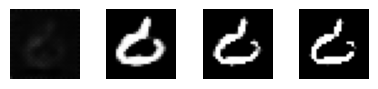

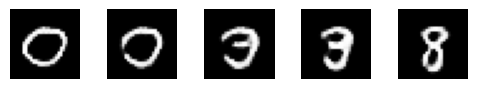

Direction utilisée : 0 vers 8


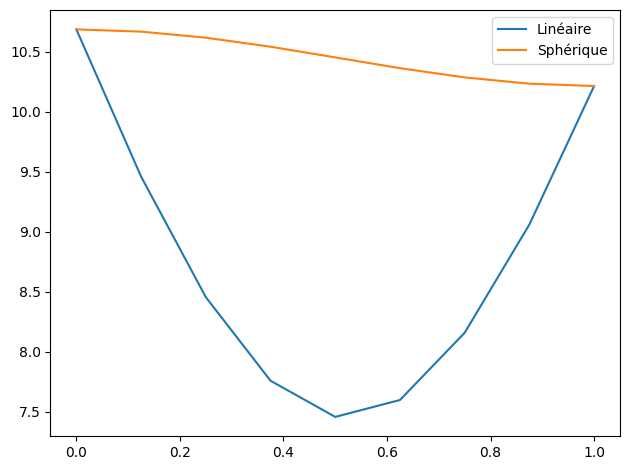

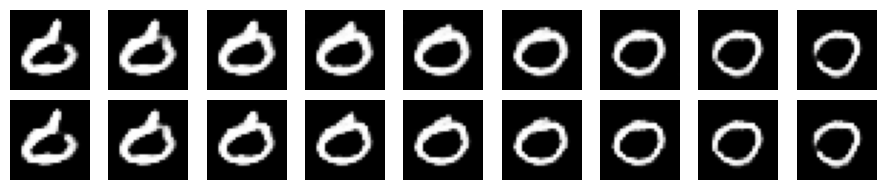

In [8]:
# Faire varier la norme à direction latente fixe.
base=z[:1];normes=[.1,1,3,10]
grille(torch.cat([code2image(base*k) for k in normes]),'norme_z',4)
# Estimer une direction entre deux classes présentes.
present=np.flatnonzero(counts>0);i,j=(0,8) if counts[0]>0 and counts[8]>0 else (int(present[0]),int(present[-1]))
mi=z[torch.tensor(pseudo==i,device=device)].mean(0);mj=z[torch.tensor(pseudo==j,device=device)].mean(0);direction=mj-mi
start=z[np.flatnonzero(pseudo==i)[0]:np.flatnonzero(pseudo==i)[0]+1];alphas=[-1,0,.5,1,2]
grille(torch.cat([code2image(start+t*direction) for t in alphas]),'direction_semantique',5);print('Direction utilisée :',i,'vers',j)
# Interpoler deux codes en évitant les instabilités lorsque les directions coïncident.
a,b=z[0],z[1];ts=torch.linspace(0,1,9,device=device);theta=torch.acos(F.cosine_similarity(a[None],b[None]).clamp(-.99999,.99999))
linear=torch.stack([(1-t)*a+t*b for t in ts]);spherical=torch.stack([(torch.sin((1-t)*theta)*a+torch.sin(t*theta)*b)/torch.sin(theta) for t in ts])
plt.plot(ts.cpu(),linear.norm(dim=1).cpu(),label='Linéaire');plt.plot(ts.cpu(),spherical.norm(dim=1).cpu(),label='Sphérique');plt.legend();figure('normes_interpolation')
grille(torch.cat([code2image(linear),code2image(spherical)]),'interpolations',9)


## Contrôle indépendant des checkpoints et barycentres de toutes les classes
Rechargement des poids et nouvel échantillon de contrôle (graine 123), distinct des 1 000 images de Q10. Les classes absentes ont un barycentre indéfini. Le fichier NPZ conserve cet échantillon latent et ses pseudo-étiquettes.

In [3]:
# Recharger les checkpoints pour vérifier leur réutilisation et calculer tous les barycentres.
dg.load_state_dict(torch.load('models/dcgan_remplacement.pt',map_location=device,weights_only=True))
clf.load_state_dict(torch.load('models/lenet5_remplacement.pt',map_location=device,weights_only=True))
dg.eval();clf.eval();torch.manual_seed(123)
z_controle=torch.randn(1000,100,device=device)
images_controle=code2image(z_controle)
assert images_controle.shape==(1000,28,28)
autre_forme=code2image(z_controle[:,:,None,None])
ecart_max=float((images_controle-autre_forme).abs().max())
print('Écart maximal entre formes de z :',ecart_max)
# Tolérance absolue explicite pour les petits écarts des convolutions CUDA près de zéro.
torch.testing.assert_close(images_controle,autre_forme,atol=1e-5,rtol=1e-4)
assert torch.isfinite(images_controle).all()
with torch.no_grad():labels_controle=clf(images_controle[:,None]).argmax(1)
barycentres={}
for classe in range(10):
    masque=labels_controle==classe
    if masque.any():barycentres[classe]=z_controle[masque].mean(0).cpu().numpy()
    print('Classe',classe,':',int(masque.sum()),'images ; barycentre', 'calculé' if masque.any() else 'indéfini (classe absente)')
# Conserver les latents et pseudo-étiquettes de ce contrôle séparé de l'échantillon Q10.
np.savez_compressed('controle_latent.npz',z=z_controle.cpu().numpy(),labels=labels_controle.cpu().numpy(),classes=np.array(list(barycentres)),barycentres=np.array(list(barycentres.values())))
print('Checkpoints rechargés ; deux formes de z concordantes à la tolérance CUDA ; sorties finies : OK')


Écart maximal entre formes de z : 2.384185791015625e-07


Classe 0 : 102 images ; barycentre calculé
Classe 1 : 83 images ; barycentre calculé
Classe 2 : 80 images ; barycentre calculé
Classe 3 : 88 images ; barycentre calculé
Classe 4 : 80 images ; barycentre calculé
Classe 5 : 103 images ; barycentre calculé
Classe 6 : 91 images ; barycentre calculé
Classe 7 : 138 images ; barycentre calculé
Classe 8 : 127 images ; barycentre calculé
Classe 9 : 108 images ; barycentre calculé
Checkpoints rechargés ; deux formes de z concordantes à la tolérance CUDA ; sorties finies : OK


## Analyse des résultats observés

Les poids DCGAN et LeNet5 sont des remplacements entraînés localement. LeNet5 atteint 97.93% d'exactitude sur les 10 000 images de test MNIST. Ce score concerne le classifieur sur des images réelles ; il ne mesure pas la qualité du générateur.

| Expérience SVM linéaire | Score observé | Interprétation |
|---|---:|---|
| Réel → réel | 90.50% | Référence : 10 000 images d'apprentissage réelles, test indépendant de 10 000 images |
| Réel → synthétique | 64.20% | Concordance avec les pseudo-étiquettes de LeNet5 |
| Synthétique → réel | 77.61% | Transfert depuis 1 000 images pseudo-étiquetées, sans égalité de taille d'apprentissage |

Les occurrences synthétiques pour les classes 0 à 9 sont : [102, 71, 107, 102, 79, 91, 85, 121, 113, 129]. Les classes les moins et les plus fréquentes ont respectivement 71 et 129 exemples. La distribution n'est donc pas parfaitement uniforme. Une différence de transfert peut provenir de la diversité et des défauts des images synthétiques, des erreurs de pseudo-étiquetage et de la différence de taille des jeux d'apprentissage. Elle ne permet pas d'isoler une seule de ces causes.

Le cercle généré couvre l'anneau avec quelques points intérieurs. Les demi-lunes ne sont pas reconstruites : la génération forme surtout une concentration triangulaire. Le Swiss roll n'est pas correctement reconstruit non plus : les points forment des branches ou des concentrations plutôt que le rouleau attendu, particulièrement avec un latent de dimension 1. Diminuer la dimension latente réduit les degrés de liberté disponibles, sans suffire à prouver une dimension intrinsèque optimale. Les trois essais Swiss roll ne sont pas des répétitions statistiques.

Le cGAN produit des formes de chiffres avec un bruit important ; les lignes ne correspondent pas systématiquement à la classe demandée. Le conditionnement one-hot est implémenté, mais le contrôle de classe n'est pas acquis de manière fiable après cette exécution de 15 époques. Un entraînement plus long, un discriminateur conditionnel plus expressif et une évaluation par classe seraient des pistes d'amélioration, sans garantie de résultat avant expérimentation.

La norme de z contrôle un déplacement hors de la zone typique de la loi d'apprentissage : les grandes amplitudes peuvent dégrader les chiffres. Les directions issues des barycentres sont des tendances statistiques, pas des transformations de classe garanties. Pour deux codes de rayons proches, la slerp limite la baisse de norme au milieu du trajet que montre l'interpolation linéaire ; elle ne garantit pas que chaque image intermédiaire soit lisible.
